# Regimes that only exist *between* windows: where can a JEPA beat cheap baselines?

In `regime_large_scale.ipynb` the regimes differ in their within-window spectra. A hand-built "PCA → per-window
spectrum → GMM" pipeline recovers them (≈ 0.88 without labels), and the JEPA objective spends its dimensions
elsewhere. That benchmark can show the JEPA's failure mode, but it can't show any value.

Here the regimes are **invisible in any single window by construction** and exist only in the map from window $t$ to
window $t+1$. Spectral and covariance features are blind to them. A predictive objective, which models exactly that
map, is not.

**Regime-dependent state** $x_t\in\mathbb R^6$ (three 2-D blocks $a,b,c$), window level:
$x_{t+1}=\rho\,Q_{S_t}x_t+\sqrt{1-\rho^2}\,\varepsilon$, $\rho=0.95$, with

| regime | $Q_S$ | what changes |
|---|---|---|
| 1 | $I$ | persistence |
| 2 | block permutation $a\to b\to c\to a$ | coupling direction (which block drives which) |
| 3 | block permutation $a\to c\to b\to a$ | the reverse coupling direction |
| 4 | $-I$ | the ±ρ sign flip of the worked example |

Every $Q_S$ is orthogonal, so $x_t\sim\mathcal N(0,I)$ in every regime: **the distribution of a single window is
identical across regimes**. The chain is sticky ($p_{\text{stay}}=0.9$).

**Regime-independent features:** two slow factors (λ = 0.5, 0.7), a window-level damped rotation, a within-window
AR texture whose amplitude is a stochastic volatility, gain drift, distractors and bursts. They're kept moderately
predictable so that §7's competition doesn't decide the outcome by itself. **Corruption:** identical to the
large-scale notebook (16 samples × 128 channels per window). Windows don't share samples, and nothing runs across
the boundary, so there is no copying shortcut.

**What the proposal's theory says** (the regime is *not* visible to the encoder, so its §6 constructions don't
apply). Pooled over regimes, $\mathbb E[x_{t+1}x_t^\top]=\rho\,\bar Q$ with $\bar Q=(P+P^\top)/4$: the state keeps
only modest linear predictability (canonical correlations ≤ 0.48). Its quadratic features are predictable at
$\rho^2\approx0.9$ but cannot tell $I$ from $-I$. A linear-predictor JEPA is therefore expected to keep the state
weakly and its second-order features strongly. The regime then has to be read **temporally** (AR-HMM on
$r_t\to r_{t+1}$, or $Z_t\to Y_{t+1}$ for separate encoders), never from one window.

**All representations are compared at the same width (32) with the same readouts.** The supervised probes on one
window and on a window pair measure what information is there; GMM, HMM and AR-HMM are unsupervised. The
representations are the cheap baselines (PCA spectra, covariances, raw statistics, raw window means), a random
encoder, the two JEPA designs, the true state (oracle readout ceiling), and a supervised classifier on window
pairs (ceiling).

## Setup (helpers shared with the other notebooks)

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ.setdefault(_v, "4")      # small matrices: many threads only oversubscribe the CPU
import math, time, itertools, warnings
from dataclasses import dataclass, field, replace
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neural_network import MLPClassifier
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print('device:', DEVICE)

device: mps


In [2]:
FAST = False
EMBED_DIM = 32                       # latent dimension of each encoder (= dimension every baseline is reduced to)
HIDDEN = 256                         # backbone width
STEPS = 1500 if FAST else 10000
BATCH = 256
LR = 1e-3
LAM = 0.1                            # SIGReg weight
SERIES = (8, 4) if FAST else (64, 16)
T_WIN = 500 if FAST else 1000
N_READ = 4000 if FAST else 8000      # contiguous test windows used by the readouts
OUT = "crosswindow_runs"
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
os.makedirs(OUT, exist_ok=True)
pal = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2, "figure.dpi": 110, "font.size": 9})

In [3]:
class SIGReg(torch.nn.Module):
    """Sketch Isotropic Gaussian Regularizer (single-GPU!)

    Verbatim from lucas-maes/le-wm, module.py (the LeWM implementation of LeJEPA's SIGReg):
    Epps-Pulley test of every random 1-D projection against N(0,1), on 17 knots in [0,3].
    """

    def __init__(self, knots=17, num_proj=1024):
        super().__init__()
        self.num_proj = num_proj
        t = torch.linspace(0, 3, knots, dtype=torch.float32)
        dt = 3 / (knots - 1)
        weights = torch.full((knots,), 2 * dt, dtype=torch.float32)
        weights[[0, -1]] = dt
        window = torch.exp(-t.square() / 2.0)
        self.register_buffer("t", t)
        self.register_buffer("phi", window)
        self.register_buffer("weights", weights * window)

    def forward(self, proj):
        """
        proj: (T, B, D)
        """
        # sample random projections
        A = torch.randn(proj.size(-1), self.num_proj, device=proj.device)
        A = A.div_(A.norm(p=2, dim=0))
        # compute the epps-pulley statistic
        x_t = (proj @ A).unsqueeze(-1) * self.t
        err = (x_t.cos().mean(-3) - self.phi).square() + x_t.sin().mean(-3).square()
        statistic = (err @ self.weights) * proj.size(-2)
        return statistic.mean()  # average over projections and time


def batch_whiten(z, eps=1e-4):
    """Exact (in-batch) Cholesky whitening: the idealised constraint of the theory (W-MSE / VAMPnet style)."""
    zc = z - z.mean(0, keepdim=True)
    cov = zc.T @ zc / (z.shape[0] - 1) + eps * torch.eye(z.shape[1], device=z.device)
    L = torch.linalg.cholesky(cov.cpu()).to(z.device)  # cholesky is not implemented on MPS
    return torch.linalg.solve_triangular(L, zc.T, upper=False).T

In [4]:
def predictable_variance(Z, Y, shared):
    """||C||_F^2 with C = E[Y_{t+1} Z_t^T] after exact (empirical) whitening of each encoder's outputs.
    For the shared design the same whitening map is used for both sides (it is one encoder)."""
    d = Z.shape[-1]
    if shared:
        Wd = whiten_map(Z.reshape(-1, d))
        Zw = Yw = (Z - Z.reshape(-1, d).mean(0)) @ Wd
    else:
        Zw = (Z - Z.reshape(-1, d).mean(0)) @ whiten_map(Z.reshape(-1, d))
        Yw = (Y - Y.reshape(-1, d).mean(0)) @ whiten_map(Y.reshape(-1, d))
    a, b = Zw[:, :-1].reshape(-1, Zw.shape[-1]), Yw[:, 1:].reshape(-1, Yw.shape[-1])
    C = b.T @ a / len(a)
    return float((C ** 2).sum()), np.linalg.svd(C, compute_uv=False)


def whiten_map(A, eps=1e-6):
    A = A - A.mean(0)
    C = A.T @ A / len(A)
    w, V = np.linalg.eigh(C)
    w = np.maximum(w, eps * max(w.max(), eps))
    return V / np.sqrt(w)


def gt_features(spec, lat):
    """Named ground-truth features per window, each (N,T,k). These are the candidate features of the theory."""
    S, x, n = lat["S"], lat["x"], lat["n"]
    K, pi = spec.K, spec.pi
    onehot = np.eye(K)[S]
    f = {"regime": onehot[..., : K - 1]} if K > 1 else {}
    f["x"] = x
    f["g (x·1[S=k])"] = np.concatenate([x * onehot[..., k: k + 1] / math.sqrt(pi[k]) for k in range(K)], -1)
    f["|x|²"] = (x ** 2).sum(-1, keepdims=True)
    if spec.m == 2:
        f["x quad. (x1²-x2², x1x2)"] = np.stack([x[..., 0] ** 2 - x[..., 1] ** 2, x[..., 0] * x[..., 1]], -1)
    if spec.q:
        f["nuisance n"] = n
        quad = [n[..., i] * n[..., j] - (i == j) for i in range(spec.q) for j in range(i, spec.q)]
        f["nuisance n²"] = np.stack(quad, -1)
    return f


def r2_table(Lat, feats, n_fit):
    """Linear R^2 of each ground-truth feature from the latent (fit on first n_fit windows, test on the rest)."""
    out = {}
    L = Lat.reshape(-1, Lat.shape[-1])
    for name, F_ in feats.items():
        Fm = F_.reshape(-1, F_.shape[-1])
        r2s = []
        for j in range(Fm.shape[1]):
            reg = LinearRegression().fit(L[:n_fit], Fm[:n_fit, j])
            res = Fm[n_fit:, j] - reg.predict(L[n_fit:])
            r2s.append(1 - res.var() / (Fm[n_fit:, j].var() + 1e-12))
        out[name] = float(np.clip(np.mean(r2s), 0, 1))
    return out


def best_perm_acc(true, pred, K):
    M = np.zeros((K, K))
    for a, b in zip(true, pred):
        M[a, b] += 1
    r, c = linear_sum_assignment(-M)
    mapping = dict(zip(c, r))
    return balanced_accuracy_score(true, [mapping.get(p, -1) for p in pred])


def switching_regression(X, Y, K, restarts=5, iters=50, seed=0):
    """Unsupervised mixture of K linear regressions Y ~ A_k [X,1] (EM). Returns hard labels."""
    rng = np.random.default_rng(seed)
    N, dy = Y.shape
    Xd = np.c_[X, np.ones(N)]
    best, best_ll = None, -np.inf
    for r in range(restarts):
        R = rng.dirichlet(np.ones(K), N)
        for it in range(iters):
            logp = np.zeros((N, K))
            for k in range(K):
                w = R[:, k] + 1e-9
                A = np.linalg.solve(Xd.T @ (Xd * w[:, None]) + 1e-6 * np.eye(Xd.shape[1]), Xd.T @ (Y * w[:, None]))
                E = Y - Xd @ A
                Sig = (E * w[:, None]).T @ E / w.sum() + 1e-4 * np.eye(dy)
                Si = np.linalg.inv(Sig)
                logp[:, k] = (np.log(w.mean()) - 0.5 * np.linalg.slogdet(Sig)[1]
                              - 0.5 * np.einsum("ni,ij,nj->n", E, Si, E))
            mx = logp.max(1, keepdims=True)
            ll = float((mx[:, 0] + np.log(np.exp(logp - mx).sum(1))).sum())
            R = np.exp(logp - mx); R /= R.sum(1, keepdims=True)
        if ll > best_ll:
            best, best_ll = R.argmax(1), ll
    return best


def regime_readouts(Z, Ysame, S, K, shared, n_fit, seed=0):
    """How the regime can be read out of the latents (balanced accuracy, chance = 1/K)."""
    d = Z.shape[-1]
    Zf, Yf, Sf = Z.reshape(-1, d), Ysame.reshape(-1, d), S.reshape(-1)
    sc = StandardScaler().fit(Zf[:n_fit]); Zs = sc.transform(Zf)
    scy = StandardScaler().fit(Yf[:n_fit]); Ys = scy.transform(Yf)
    out = {}
    lin = LogisticRegression(max_iter=2000).fit(Zs[:n_fit], Sf[:n_fit])
    out["probe lin(Z)"] = balanced_accuracy_score(Sf[n_fit:], lin.predict(Zs[n_fit:]))
    mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(Zs[:n_fit], Sf[:n_fit])
    out["probe MLP(Z)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(Zs[n_fit:]))
    gm = GaussianMixture(K, n_init=3, random_state=seed).fit(Zs[:n_fit])
    lab = gm.predict(Zs[n_fit:])
    out["GMM(Z) acc"] = best_perm_acc(Sf[n_fit:], lab, K)
    if not shared:
        mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(Ys[:n_fit], Sf[:n_fit])
        out["probe MLP(Y)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(Ys[n_fit:]))
        ZY = np.c_[Zs, Ys]
        mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(ZY[:n_fit], Sf[:n_fit])
        out["probe MLP(Z,Y)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(ZY[n_fit:]))
        lab = switching_regression(Zs[n_fit:], Ys[n_fit:], K, seed=seed)
        out["switch-reg(Z→Y)"] = best_perm_acc(Sf[n_fit:], lab, K)
        if d == 1 and K == 2:
            out["sign(z·y)"] = best_perm_acc(Sf[n_fit:], (Zs[n_fit:, 0] * Ys[n_fit:, 0] > 0).astype(int), 2)
    return out


def evaluate_latents(Z, Y, spec, lat, shared, n_eval=8000, seed=0, clusters=True):
    """Z, Y: (N,T,d) context / target-encoder outputs on the SAME windows."""
    score, sv = predictable_variance(Z, Y, shared)
    feats = gt_features(spec, lat)
    N, T, d = Z.shape
    take = min(N * T, n_eval)
    idx = np.random.default_rng(seed).permutation(N * T)[:take]
    sub = lambda A: A.reshape(N * T, -1)[idx][None]
    n_fit = int(0.6 * take)
    fsub = {k: sub(v) for k, v in feats.items()}
    res = dict(score=score, canon=np.round(sv, 3))
    res.update({f"R²Z {k}": v for k, v in r2_table(sub(Z), fsub, n_fit).items()})
    if not shared:
        res.update({f"R²Y {k}": v for k, v in r2_table(sub(Y), fsub, n_fit).items()})
    if spec.K > 1:
        res.update(regime_readouts(sub(Z), sub(Y), sub(lat["S"][..., None])[..., 0], spec.K, shared, n_fit, seed))
        if clusters:
            res.update({f"clu {k}": v for k, v in cluster_battery(Z, lat["S"], spec.K, None if shared else Y, seed=seed).items()})
    cov = np.cov(Z.reshape(-1, d).T).reshape(d, d)
    ev = np.linalg.eigvalsh(cov)
    res["latent cov eig (min,max)"] = (round(float(ev.min()), 2), round(float(ev.max()), 2))
    return res

In [5]:
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA


def _forward_backward(logB, A, pi, lengths):
    """Scaled forward-backward over several sequences. Returns posteriors, expected transition counts, log-lik."""
    N, K = logB.shape
    gamma, xi, ll, start = np.zeros((N, K)), np.zeros((K, K)), 0.0, 0
    for L in lengths:
        lb = logB[start: start + L]
        m = lb.max(1, keepdims=True)
        B = np.exp(lb - m)
        alpha, c = np.zeros((L, K)), np.zeros(L)
        a = pi * B[0]; c[0] = a.sum() + 1e-300; alpha[0] = a / c[0]
        for t in range(1, L):
            a = (alpha[t - 1] @ A) * B[t]; c[t] = a.sum() + 1e-300; alpha[t] = a / c[t]
        beta = np.ones((L, K))
        for t in range(L - 2, -1, -1):
            beta[t] = (A @ (B[t + 1] * beta[t + 1])) / c[t + 1]
        g = alpha * beta
        gamma[start: start + L] = g / g.sum(1, keepdims=True)
        xi += A * (alpha[:-1].T @ (B[1:] * beta[1:] / c[1:, None]))
        ll += np.log(c).sum() + m.sum()
        start += L
    return gamma, xi, ll


def hmm_regression(X, Y, K, lengths, iters=40, restarts=3, seed=0, init=None):
    """HMM whose hidden state k emits Y_t ~ N(A_k [X_t, 1], Σ_k), fitted by Baum-Welch.
    X=None: Gaussian HMM. X=z_t, Y=z_{t+1}: autoregressive HMM (temporal switching regression).
    X=Z, Y=Y on the same input: the switching regression of §6 with a Markov prior on the regime."""
    rng = np.random.default_rng(seed)
    N, dy = Y.shape
    Xd = np.ones((N, 1)) if X is None else np.c_[X, np.ones(N)]
    best, best_ll = None, -np.inf
    for r in range(restarts):
        R = np.eye(K)[init] * 0.8 + 0.2 / K if (r == 0 and init is not None) else rng.dirichlet(np.ones(K), N)
        A = np.full((K, K), 0.1 / max(K - 1, 1)); np.fill_diagonal(A, 0.9)
        pi = np.full(K, 1 / K)
        for it in range(iters):
            logB = np.zeros((N, K))
            for k in range(K):
                w = R[:, k] + 1e-9
                Ak = np.linalg.solve(Xd.T @ (Xd * w[:, None]) + 1e-6 * np.eye(Xd.shape[1]), Xd.T @ (Y * w[:, None]))
                E = Y - Xd @ Ak
                Sig = (E * w[:, None]).T @ E / w.sum() + 1e-4 * np.eye(dy)
                logB[:, k] = -0.5 * np.linalg.slogdet(Sig)[1] - 0.5 * np.einsum("ni,ij,nj->n", E, np.linalg.inv(Sig), E)
            R, xi, ll = _forward_backward(logB, A, pi, lengths)
            A = xi / xi.sum(1, keepdims=True)
        if ll > best_ll:
            best, best_ll = R.argmax(1), ll
    return best


def tsc_cluster(Z, K, q=20, seed=0):
    """Thresholding-based subspace clustering (Heckel & Bölcskei, 2015): each point is linked to its q neighbours in
    absolute cosine similarity, then spectral clustering. Recovers unions of subspaces (regime-specific directions,
    the 'g' features) and is designed for high dimension."""
    Zn = Z - Z.mean(0)
    Zn = Zn / (np.linalg.norm(Zn, axis=1, keepdims=True) + 1e-12)
    C = np.abs(Zn @ Zn.T); np.fill_diagonal(C, 0)
    idx = np.argpartition(-C, q, axis=1)[:, :q]
    rows = np.repeat(np.arange(len(Z)), q)
    vals = np.exp(-2 * np.arccos(np.clip(C[rows, idx.reshape(-1)], 0, 1)))
    from scipy.sparse import csr_matrix
    W = csr_matrix((vals, (rows, idx.reshape(-1))), shape=C.shape)
    W = W + W.T
    return SpectralClustering(K, affinity="precomputed", random_state=seed, assign_labels="cluster_qr").fit_predict(W)


def cluster_battery(Z, S, K, Y=None, n_windows=4000, pcs=8, seed=0):
    """Unsupervised regime recovery from a latent, using contiguous windows (n_series, T, d), so temporal methods apply.
    Every method is scored by balanced accuracy after the best label permutation (chance 1/K)."""
    n_ser = max(1, min(Z.shape[0], int(np.ceil(n_windows / Z.shape[1]))))
    T = min(Z.shape[1], n_windows // n_ser)
    Zc, Sc = Z[:n_ser, :T], S[:n_ser, :T].reshape(-1)
    d = Z.shape[-1]
    flat = StandardScaler().fit_transform(Zc.reshape(-1, d))
    k = min(d, pcs)
    P = PCA(k, whiten=True, random_state=seed).fit_transform(flat) if d > k else flat
    out = {}
    gm = GaussianMixture(K, n_init=3, random_state=seed).fit(P)
    g_lab = gm.predict(P)
    out["GMM"] = best_perm_acc(Sc, g_lab, K)
    out["spectral kNN"] = best_perm_acc(Sc, SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=15,
                                                               random_state=seed, assign_labels="cluster_qr").fit_predict(P), K)
    if d >= 2:
        out["subspace (TSC)"] = best_perm_acc(Sc, tsc_cluster(flat, K, seed=seed), K)
    lengths = [T] * n_ser
    out["HMM"] = best_perm_acc(Sc, hmm_regression(None, P, K, lengths, seed=seed, init=g_lab), K)
    Pm = P.reshape(n_ser, T, -1)
    X_ar, Y_ar = Pm[:, :-1].reshape(-1, k), Pm[:, 1:].reshape(-1, k)
    S_ar = S[:n_ser, :T - 1].reshape(-1)          # S_t governs z_t -> z_{t+1}
    init_ar = g_lab.reshape(n_ser, T)[:, :-1].reshape(-1)
    out["AR-HMM (z_t→z_t+1)"] = best_perm_acc(S_ar, hmm_regression(X_ar, Y_ar, K, [T - 1] * n_ser, seed=seed, init=init_ar), K)
    if Y is not None:
        Yf = StandardScaler().fit_transform(Y[:n_ser, :T].reshape(-1, d))
        Q = PCA(k, whiten=True, random_state=seed).fit_transform(Yf) if d > k else Yf
        out["HMM switch-reg (Z→Y)"] = best_perm_acc(Sc, hmm_regression(P, Q, K, lengths, seed=seed), K)
    return out

Corruption and encoder classes, identical to `regime_large_scale.ipynb`:

In [6]:
@dataclass
class BigSpec:
    K: int = 4
    p_stay: float = 0.9
    W: int = 32                                   # samples per window
    D: int = 128                                  # observed channels
    # regime-dependent state: 3 rotation planes; regime k sets each plane's frequency (cycles/sample) and damping
    reg_freqs: tuple = ((0.05, 0.12, 0.20), (0.12, 0.20, 0.05), (0.20, 0.05, 0.12), (0.08, 0.16, 0.26))
    reg_damp: tuple = (0.99, 0.99, 0.99, 0.97)
    # regime-independent features of different types
    slow_lams: tuple = (0.9, 0.95, 0.97)          # slow AR factors (window-level autocorrelation)
    osc_freqs: tuple = (0.03, 0.31)               # fixed-frequency oscillators (2 planes)
    osc_damp: float = 0.995
    vol_lam: float = 0.95                         # stochastic volatility (log-vol AR, window-level)
    vol_scale: float = 0.8
    gain_lam: float = 0.98                        # multiplicative sensor-gain drift
    gain_scale: float = 0.25
    n_distract: int = 4                           # white distractors (unpredictable)
    burst_rate: float = 0.02                      # heavy-tailed bursts (unpredictable)
    # corruption
    couplings: int = 4                            # invertible affine coupling layers
    coupling_strength: float = 1.0
    saturation: float = 3.0                       # soft clip a·tanh(o/a)
    lowpass_max: float = 0.6                      # per-channel first-order sensor dynamics within a window
    obs_noise: float = 0.2
    outliers: float = 0.01
    dropout: float = 0.05                         # whole channel missing in a window
    seed: int = 0

    @property
    def n_lat(self):
        return 6 + len(self.slow_lams) + 2 * len(self.osc_freqs) + 1 + self.n_distract + 1


def _rot(f, r):
    a = 2 * np.pi * f
    return r * np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])


def simulate_big(spec, n_series, T, rng):
    """Sample-level latent process. Regimes switch at window boundaries (Markov, p_stay); every component has unit
    stationary variance. Returns per-sample latents u (N,T,W,n_lat), log-gain (N,T,W) and window-level labels."""
    K, W = spec.K, spec.W
    P = np.full((K, K), (1 - spec.p_stay) / (K - 1)); np.fill_diagonal(P, spec.p_stay)
    S = np.zeros((n_series, T), int); S[:, 0] = rng.integers(K, size=n_series)
    cum = P.cumsum(1)
    for t in range(1, T):
        S[:, t] = (rng.random(n_series)[:, None] > cum[S[:, t - 1]]).sum(1)
    B = np.stack([np.block([
        [_rot(spec.reg_freqs[k][0], spec.reg_damp[k]), np.zeros((2, 4))],
        [np.zeros((2, 2)), _rot(spec.reg_freqs[k][1], spec.reg_damp[k]), np.zeros((2, 2))],
        [np.zeros((2, 4)), _rot(spec.reg_freqs[k][2], spec.reg_damp[k])]]) for k in range(K)])
    sd_reg = np.sqrt(1 - np.array(spec.reg_damp) ** 2)
    a_slow = np.array(spec.slow_lams) ** (1 / W)
    Bo = [_rot(f, spec.osc_damp) for f in spec.osc_freqs]
    a_vol, a_gain = spec.vol_lam ** (1 / W), spec.gain_lam ** (1 / W)
    n_s, n_o = len(spec.slow_lams), 2 * len(spec.osc_freqs)
    N, TW = n_series, T * W
    x = rng.standard_normal((N, 6)); slow = rng.standard_normal((N, n_s)); osc = rng.standard_normal((N, n_o))
    h = rng.standard_normal(N); G = rng.standard_normal(N)
    X = np.zeros((N, TW, 6), np.float32); SL = np.zeros((N, TW, n_s), np.float32)
    OS = np.zeros((N, TW, n_o), np.float32); H = np.zeros((N, TW), np.float32); GG = np.zeros((N, TW), np.float32)
    for s in range(TW):
        k = S[:, s // W]
        x = np.einsum("nij,nj->ni", B[k], x) + sd_reg[k][:, None] * rng.standard_normal((N, 6))
        slow = a_slow * slow + np.sqrt(1 - a_slow ** 2) * rng.standard_normal((N, n_s))
        osc = np.concatenate([osc[:, 2 * i: 2 * i + 2] @ Bo[i].T for i in range(len(Bo))], 1) \
            + math.sqrt(1 - spec.osc_damp ** 2) * rng.standard_normal((N, n_o))
        h = a_vol * h + math.sqrt(1 - a_vol ** 2) * rng.standard_normal(N)
        G = a_gain * G + math.sqrt(1 - a_gain ** 2) * rng.standard_normal(N)
        X[:, s], SL[:, s], OS[:, s], H[:, s], GG[:, s] = x, slow, osc, h, G
    vol = np.exp(spec.vol_scale * H - spec.vol_scale ** 2) * rng.standard_normal((N, TW))
    distract = rng.standard_normal((N, TW, spec.n_distract))
    burst = (rng.random((N, TW)) < spec.burst_rate) * rng.standard_t(3, (N, TW)) * 3
    u = np.concatenate([X, SL, OS, vol[..., None], distract, burst[..., None]], -1).astype(np.float32)
    r = lambda A: A.reshape(N, T, W, *A.shape[2:])
    return dict(S=S, u=r(u), logg=r(spec.gain_scale * GG), x=r(X), slow=r(SL), osc=r(OS), h=r(H), G=r(GG))


class Corruptor(nn.Module):
    """Fixed random map latent (n_lat) -> D channels: up-projection, invertible affine couplings, soft saturation,
    multiplicative gain drift, per-channel low-pass sensor dynamics, noise, outliers, channel dropout.
    Everything before the noise is invertible (couplings) or monotone (saturation, gain, causal filter)."""

    def __init__(self, spec):
        super().__init__()
        g = torch.Generator().manual_seed(1000 + spec.seed)
        D, L = spec.D, spec.n_lat
        Q, _ = torch.linalg.qr(torch.randn(D, L, generator=g))
        self.register_buffer("P", Q * math.sqrt(D / L))                    # orthonormal columns -> injective
        self.perms = [torch.randperm(D, generator=g) for _ in range(spec.couplings)]
        h = D // 2
        self.A = nn.ParameterList([nn.Parameter(torch.randn(h, h, generator=g) * 1.5 / math.sqrt(h), requires_grad=False) for _ in range(spec.couplings)])
        self.C = nn.ParameterList([nn.Parameter(torch.randn(h, h, generator=g) * 1.5 / math.sqrt(h), requires_grad=False) for _ in range(spec.couplings)])
        self.register_buffer("alpha", torch.rand(D, generator=g) * spec.lowpass_max)
        self.spec = spec
        self.register_buffer("mu", torch.zeros(D)); self.register_buffer("sd", torch.ones(D))

    def clean(self, u, logg):
        s = self.spec
        o = u @ self.P.T
        h = s.D // 2
        for perm, A, C in zip(self.perms, self.A, self.C):
            o = o[..., perm.to(o.device)]
            a, b = o[..., :h], o[..., h:]
            b = b * torch.exp(0.5 * s.coupling_strength * torch.tanh(a @ A.T)) + s.coupling_strength * torch.tanh(a @ C.T)
            o = torch.cat([a, b], -1)
        o = s.saturation * torch.tanh(o / s.saturation)
        o = o * torch.exp(logg)[..., None]
        out, prev = [], o[:, 0]
        for t in range(o.shape[1]):                                       # filter within the window only
            prev = self.alpha * prev + (1 - self.alpha) * o[:, t]
            out.append(prev)
        return torch.stack(out, 1)

    def forward(self, u, logg, gen=None):
        s = self.spec
        o = self.clean(u, logg)
        o = o + s.obs_noise * torch.randn(o.shape, device=o.device, generator=gen)
        hit = torch.rand(o.shape, device=o.device, generator=gen) < s.outliers
        o = torch.where(hit, o + 5 * torch.randn(o.shape, device=o.device, generator=gen), o)
        keep = (torch.rand(o.shape[0], 1, o.shape[2], device=o.device, generator=gen) > s.dropout).float()
        return (o * keep - self.mu) / self.sd


def window_features(spec, lat):
    """Window-level ground truth, grouped by type (used for R² and the oracle)."""
    S, K = lat["S"], spec.K
    oh = np.eye(K)[S]
    x_end = lat["x"][:, :, -1]
    f = dict()
    f["regime indicator"] = oh[..., : K - 1]
    f["regime state x"] = x_end
    f["g = x·1[S=k]"] = np.concatenate([x_end * oh[..., k: k + 1] for k in range(K)], -1)
    xs = lat["x"]
    f["state energy per plane"] = np.stack([(xs[..., 2 * i: 2 * i + 2] ** 2).sum(-1).mean(-1) for i in range(3)], -1)
    f["slow factors"] = lat["slow"].mean(2)
    sl = f["slow factors"]
    f["slow factors²"] = np.stack([sl[..., i] * sl[..., j] for i in range(sl.shape[-1]) for j in range(i, sl.shape[-1])], -1)
    f["oscillators"] = lat["osc"][:, :, -1]
    f["log-volatility"] = lat["h"].mean(2)[..., None]
    f["gain drift"] = lat["G"].mean(2)[..., None]
    f["distractors"] = lat["u"][..., -1 - spec.n_distract: -1].mean(2)
    return f

In [7]:
class BigTCN(nn.Module):
    def __init__(self, D, H, levels=5, k=3):
        super().__init__()
        self.inp = nn.Conv1d(D, H, 1)
        self.blocks = nn.ModuleList([nn.Sequential(
            nn.Conv1d(H, H, k, dilation=2 ** i, padding=2 ** i), nn.GroupNorm(8, H), nn.GELU(),
            nn.Conv1d(H, H, k, dilation=2 ** i, padding=2 ** i)) for i in range(levels)])
        self.out_dim = 2 * H

    def forward(self, x):
        h = self.inp(x.transpose(1, 2))
        for b in self.blocks:
            h = h + b(F.gelu(h))
        h = F.gelu(h)
        return torch.cat([h.mean(-1), h.amax(-1)], -1)


class BigEncoder(nn.Module):
    def __init__(self, D, d, H):
        super().__init__()
        self.phi = BigTCN(D, H)
        self.proj = nn.Sequential(nn.Linear(self.phi.out_dim, 2 * H), nn.BatchNorm1d(2 * H), nn.GELU(), nn.Linear(2 * H, d))

    def forward(self, x):
        return self.proj(self.phi(x))


class BigJEPA(nn.Module):
    def __init__(self, design, d=EMBED_DIM, H=HIDDEN, predictor="linear"):
        super().__init__()
        self.design = design
        self.ctx = BigEncoder(spec.D, d, H)
        self.tgt = self.ctx if design == "shared" else BigEncoder(spec.D, d, H)
        self.pred = nn.Linear(d, d, bias=False) if predictor == "linear" else nn.Sequential(
            nn.Linear(d, 512), nn.GELU(), nn.Linear(512, d))
        self.sigreg = SIGReg()

    def losses(self, xc, xn):
        if self.design == "shared":
            out = self.ctx(torch.cat([xc, xn])); z, y = out.chunk(2); reg = self.sigreg(out[None])
        else:
            z, y = self.ctx(xc), self.tgt(xn); reg = 0.5 * (self.sigreg(z[None]) + self.sigreg(y[None]))
        return (y - self.pred(z)).square().mean(), reg

## Generator

In [8]:
def _blockperm(perm):
    Pm = np.zeros((6, 6))
    for i, j in enumerate(perm):
        Pm[2 * j: 2 * j + 2, 2 * i: 2 * i + 2] = np.eye(2)       # block i is sent to block j
    return Pm

@dataclass
class CWSpec:
    K: int = 4
    p_stay: float = 0.9
    rho: float = 0.95
    W: int = 16
    D: int = 128
    # regime-independent features (window level unless stated)
    slow_lams: tuple = (0.5, 0.7)
    osc_angle: float = 0.6                # window-level rotation of a 2-D oscillator
    osc_damp: float = 0.8
    texture_ar: float = 0.7               # sample-level AR(1) texture, reset every window, amplitude = volatility
    vol_lam: float = 0.8
    vol_scale: float = 0.6
    gain_lam: float = 0.9
    gain_scale: float = 0.25
    n_distract: int = 4
    burst_rate: float = 0.02
    jitter: float = 0.1
    # corruption (same Corruptor as the large-scale notebook)
    couplings: int = 4
    coupling_strength: float = 1.0
    saturation: float = 3.0
    lowpass_max: float = 0.6
    obs_noise: float = 0.2
    outliers: float = 0.01
    dropout: float = 0.05
    seed: int = 0

    @property
    def Q(self):
        return [np.eye(6), _blockperm([1, 2, 0]), _blockperm([2, 0, 1]), -np.eye(6)]

    @property
    def n_lat(self):
        return 6 + len(self.slow_lams) + 2 + 2 + self.n_distract + 1

REGIME_NAMES = ["persist (I)", "a→b→c", "a→c→b", "sign flip (−I)"]


def simulate_cw(spec, n_series, T, rng):
    """Window-level process. Every regime map is orthogonal, so x_t ~ N(0, I) whatever the regime: a single window
    carries no information about the regime; only the map from window t to window t+1 does."""
    K, W, N = spec.K, spec.W, n_series
    P = np.full((K, K), (1 - spec.p_stay) / (K - 1)); np.fill_diagonal(P, spec.p_stay)
    S = np.zeros((N, T), int); S[:, 0] = rng.integers(K, size=N)
    cum = P.cumsum(1)
    for t in range(1, T):
        S[:, t] = (rng.random(N)[:, None] > cum[S[:, t - 1]]).sum(1)
    Q = np.stack(spec.Q)
    x = np.zeros((N, T, 6)); x[:, 0] = rng.standard_normal((N, 6))
    ns = len(spec.slow_lams); lam = np.array(spec.slow_lams)
    slow = np.zeros((N, T, ns)); slow[:, 0] = rng.standard_normal((N, ns))
    a = spec.osc_angle; Ro = spec.osc_damp * np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    osc = np.zeros((N, T, 2)); osc[:, 0] = rng.standard_normal((N, 2))
    h = np.zeros((N, T)); G = np.zeros((N, T)); h[:, 0] = rng.standard_normal(N); G[:, 0] = rng.standard_normal(N)
    for t in range(1, T):
        x[:, t] = spec.rho * np.einsum("nij,nj->ni", Q[S[:, t - 1]], x[:, t - 1]) + math.sqrt(1 - spec.rho ** 2) * rng.standard_normal((N, 6))
        slow[:, t] = lam * slow[:, t - 1] + np.sqrt(1 - lam ** 2) * rng.standard_normal((N, ns))
        osc[:, t] = osc[:, t - 1] @ Ro.T + math.sqrt(1 - spec.osc_damp ** 2) * rng.standard_normal((N, 2))
        h[:, t] = spec.vol_lam * h[:, t - 1] + math.sqrt(1 - spec.vol_lam ** 2) * rng.standard_normal(N)
        G[:, t] = spec.gain_lam * G[:, t - 1] + math.sqrt(1 - spec.gain_lam ** 2) * rng.standard_normal(N)
    # sample level: window value + jitter; texture is AR(1) within the window and restarts every window
    rep = lambda A: np.repeat(A[:, :, None], W, 2)
    jit = lambda A: rep(A) + spec.jitter * rng.standard_normal((N, T, W, A.shape[-1]))
    tex = np.zeros((N, T, W, 2)); tex[:, :, 0] = rng.standard_normal((N, T, 2))
    for s in range(1, W):
        tex[:, :, s] = spec.texture_ar * tex[:, :, s - 1] + math.sqrt(1 - spec.texture_ar ** 2) * rng.standard_normal((N, T, 2))
    tex = tex * np.exp(spec.vol_scale * h - spec.vol_scale ** 2)[:, :, None, None]
    distract = rep(rng.standard_normal((N, T, spec.n_distract)))
    burst = ((rng.random((N, T, W)) < spec.burst_rate) * rng.standard_t(3, (N, T, W)) * 3)[..., None]
    u = np.concatenate([jit(x), jit(slow), jit(osc), tex, distract, burst], -1).astype(np.float32)
    logg = np.repeat((spec.gain_scale * G)[:, :, None], W, 2).astype(np.float32)
    return dict(S=S, u=u, logg=logg, x=x, slow=slow, osc=osc, h=h, G=G)

In [9]:
spec = CWSpec()
rng = np.random.default_rng(spec.seed)
t0 = time.time()
train_lat, test_lat = simulate_cw(spec, SERIES[0], T_WIN, rng), simulate_cw(spec, SERIES[1], T_WIN, rng)
print(f"simulated in {time.time()-t0:.0f}s: train {train_lat['u'].shape}, test {test_lat['u'].shape}")
corr = Corruptor(spec).to(DEVICE)
U_tr = torch.tensor(train_lat["u"], device=DEVICE); LG_tr = torch.tensor(train_lat["logg"], device=DEVICE)
with torch.no_grad():
    i = torch.randint(SERIES[0], (2048,)); t = torch.randint(T_WIN, (2048,))
    o = corr(U_tr[i, t], LG_tr[i, t])
    corr.mu.copy_(o.mean((0, 1))); corr.sd.copy_(o.std((0, 1)) + 1e-6)

# fixed, deterministic rendering of the test set (all test windows, in order)
with torch.no_grad():
    c_cpu = corr.to("cpu")
    OBS_TEST = torch.cat([c_cpu(torch.tensor(test_lat["u"][s]), torch.tensor(test_lat["logg"][s]),
                                gen=torch.Generator().manual_seed(10_000 + s)) for s in range(SERIES[1])]).reshape(SERIES[1], T_WIN, spec.W, spec.D)
    corr.to(DEVICE)
S_TEST = test_lat["S"]
n_read_series = max(1, N_READ // T_WIN)

simulated in 0s: train (64, 1000, 16, 17), test (16, 1000, 16, 17)


### Sanity check: invisible in one window, visible across windows
Left two panels: within-window statistics of the observations, which should overlap for all regimes. Right two
panels: the clean state across consecutive windows. The regimes appear as different slopes and couplings.

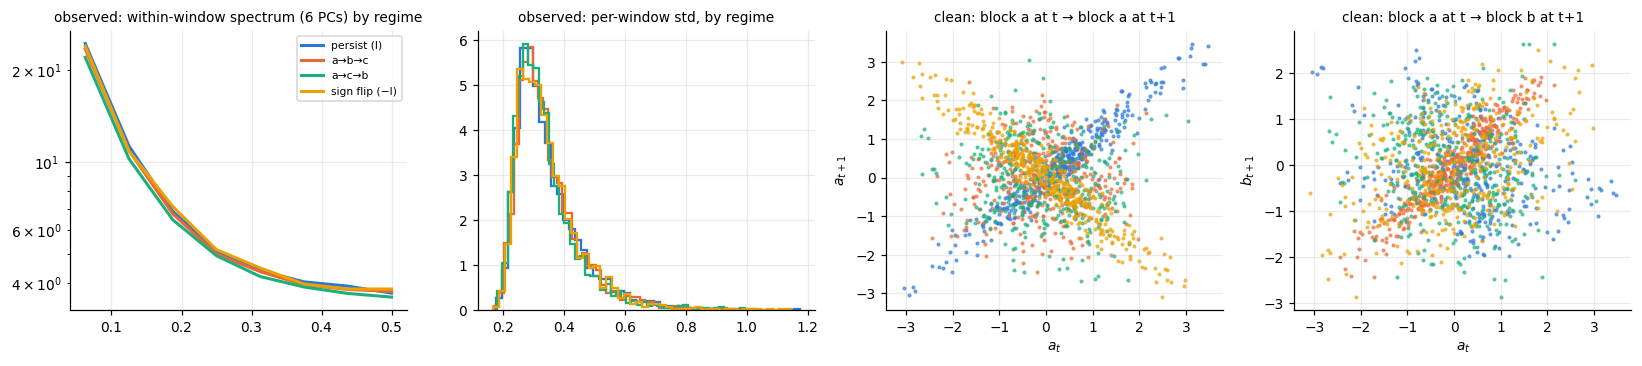

In [10]:
# The regime must be invisible in a single window and visible only across windows. Check both on the clean state
# and on the observations.
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
O = OBS_TEST.numpy()
Pobs = PCA(6).fit(O.reshape(-1, spec.D)[::5]).transform(O.reshape(-1, spec.D)).reshape(SERIES[1], T_WIN, spec.W, 6)
freqs = np.fft.rfftfreq(spec.W)
for k in range(spec.K):
    m = S_TEST == k
    sp = (np.abs(np.fft.rfft(Pobs[m] - Pobs[m].mean(1, keepdims=True), axis=1)) ** 2).mean((0, 2))
    axs[0].semilogy(freqs[1:], sp[1:], color=pal[k], label=REGIME_NAMES[k])
    axs[1].hist(O[m].std(1).mean(-1), bins=50, histtype="step", color=pal[k], density=True, lw=1.5)
xa, xb = test_lat["x"][:, :-1], test_lat["x"][:, 1:]
for k in range(spec.K):
    m = S_TEST[:, :-1] == k
    axs[2].scatter(xa[m][:400, 0], xb[m][:400, 0], s=3, color=pal[k], alpha=.6, label=REGIME_NAMES[k])
    axs[3].scatter(xa[m][:400, 0], xb[m][:400, 2], s=3, color=pal[k], alpha=.6)
axs[0].set_title("observed: within-window spectrum (6 PCs) by regime", fontsize=9); axs[0].legend(fontsize=7)
axs[1].set_title("observed: per-window std, by regime", fontsize=9)
axs[2].set_title("clean: block a at t → block a at t+1", fontsize=9); axs[2].set_xlabel("$a_t$"); axs[2].set_ylabel("$a_{t+1}$")
axs[3].set_title("clean: block a at t → block b at t+1", fontsize=9); axs[3].set_xlabel("$a_t$"); axs[3].set_ylabel("$b_{t+1}$")
plt.tight_layout(); plt.show()

## Models and readouts

In [11]:
class PairClassifier(nn.Module):
    """Supervised ceiling: the same backbone on two consecutive windows (the regime is only visible across them)."""
    def __init__(self):
        super().__init__()
        self.enc = BigEncoder(spec.D, 64, HIDDEN)
        self.head = nn.Sequential(nn.GELU(), nn.Linear(128, spec.K))

    def forward(self, a, b):
        return self.head(torch.cat([self.enc(a), self.enc(b)], -1))


def batch_pairs(batch):
    i = torch.randint(SERIES[0], (batch,), device=DEVICE); t = torch.randint(T_WIN - 1, (batch,), device=DEVICE)
    with torch.no_grad():
        return corr(U_tr[i, t], LG_tr[i, t]), corr(U_tr[i, t + 1], LG_tr[i, t + 1]), i, t


def train_cw(design, steps=STEPS, seed=0):
    path = f"{OUT}/jepa_{design}_d{EMBED_DIM}.pt"
    torch.manual_seed(seed)
    model = BigJEPA(design).to(DEVICE)
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=DEVICE)); print("loaded", path)
        return model.eval()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=steps, pct_start=0.05)
    t0 = time.time()
    for step in range(steps):
        xc, xn, _, _ = batch_pairs(BATCH)
        pred, rg = model.losses(xc, xn)
        loss = pred + LAM * rg
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sched.step()
        if step % 1000 == 0 or step == steps - 1:
            msg = f"[jepa {design}] step {step:6d} {time.time()-t0:6.0f}s pred {pred.item():.3f} sigreg {rg.item():.3f}"
            print(msg, flush=True)
            with open(f"{OUT}/progress.log", "a") as f:
                f.write(time.strftime("%H:%M:%S ") + msg + "\n")
    torch.save(model.state_dict(), path)
    return model.eval()


def train_ceiling(steps=STEPS // 2):
    path = f"{OUT}/supervised_pairs.pt"
    clf = PairClassifier().to(DEVICE)
    if os.path.exists(path):
        clf.load_state_dict(torch.load(path, map_location=DEVICE)); return clf.eval()
    S_tr = torch.tensor(train_lat["S"], device=DEVICE)
    opt = torch.optim.AdamW(clf.parameters(), lr=LR)
    for step in range(steps):
        a, b, i, t = batch_pairs(BATCH)
        loss = F.cross_entropy(clf(a, b), S_tr[i, t])
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 1000 == 0:
            with open(f"{OUT}/progress.log", "a") as f:
                f.write(time.strftime("%H:%M:%S ") + f"[supervised pairs] step {step} loss {loss.item():.3f}\n")
    torch.save(clf.state_dict(), path)
    return clf.eval()


@torch.no_grad()
def encode_windows(fn, bs=2000):
    flat = OBS_TEST.reshape(-1, spec.W, spec.D)
    out = torch.cat([fn(flat[i: i + bs].to(DEVICE)).cpu() for i in range(0, len(flat), bs)])
    return out.reshape(SERIES[1], T_WIN, -1).numpy().astype(np.float64)

In [12]:
def reduce_to(R, k=EMBED_DIM):
    """Standardise; reduce to k dims with PCA if wider (every representation is compared at the same width)."""
    f = R.reshape(-1, R.shape[-1])
    f = (f - f.mean(0)) / (f.std(0) + 1e-9)
    if f.shape[1] > k:
        f = PCA(k, random_state=0).fit(f[::3]).transform(f)
    return f.reshape(R.shape[0], R.shape[1], -1)


def readouts(R, name, Ynext=None, seed=0):
    """All readouts on contiguous windows of the first test series. Balanced accuracy, chance 0.25."""
    R = reduce_to(R)[:n_read_series]
    S = S_TEST[:n_read_series]
    n, T, d = R.shape
    out = dict(representation=name)
    # supervised probes (fit on the first 60 % of windows)
    Rf, Sf = R.reshape(-1, d), S.reshape(-1)
    cut = int(0.6 * len(Rf))
    m1 = MLPClassifier((128, 128), max_iter=200, early_stopping=True, random_state=seed).fit(Rf[:cut], Sf[:cut])
    out["probe: one window"] = balanced_accuracy_score(Sf[cut:], m1.predict(Rf[cut:]))
    Pr = np.concatenate([R[:, :-1], R[:, 1:]], -1).reshape(-1, 2 * d); Sp = S[:, :-1].reshape(-1)
    cut = int(0.6 * len(Pr))
    m2 = MLPClassifier((128, 128), max_iter=200, early_stopping=True, random_state=seed).fit(Pr[:cut], Sp[:cut])
    out["probe: window pair"] = balanced_accuracy_score(Sp[cut:], m2.predict(Pr[cut:]))
    # unsupervised
    K = spec.K
    gm = GaussianMixture(K, n_init=3, reg_covar=1e-3, random_state=seed).fit(Rf)
    g_lab = gm.predict(Rf)
    out["GMM"] = best_perm_acc(Sf, g_lab, K)
    out["HMM"] = best_perm_acc(Sf, hmm_regression(None, Rf, K, [T] * n, seed=seed, init=g_lab), K)
    Xa, Ya = R[:, :-1].reshape(-1, d), (R if Ynext is None else reduce_to(Ynext)[:n_read_series])[:, 1:].reshape(-1, d)
    out["AR-HMM r_t→r_t+1" if Ynext is None else "AR-HMM Z_t→Y_t+1"] = best_perm_acc(
        Sp, hmm_regression(Xa, Ya, K, [T - 1] * n, seed=seed), K)
    print(f"  {name:<34} " + "  ".join(f"{k}={v:.2f}" for k, v in out.items() if k != "representation"), flush=True)
    return out

## Baselines and the supervised ceiling

In [13]:
def raw_stats(o):
    m, s = o.mean(1), o.std(1)
    oc = o - o.mean(1, keepdim=True)
    ac1 = (oc[:, 1:] * oc[:, :-1]).mean(1) / (s ** 2 + 1e-6)
    return torch.cat([m, s, ac1], -1)

O_flat = OBS_TEST.reshape(-1, spec.W, spec.D).numpy()
pca6 = PCA(6, random_state=0).fit(O_flat.reshape(-1, spec.D)[::7])
P6 = pca6.transform(O_flat.reshape(-1, spec.D)).reshape(-1, spec.W, 6)
P6c = P6 - P6.mean(1, keepdims=True)
spectra = np.log(np.abs(np.fft.rfft(P6c, axis=1)) ** 2 + 1e-6).reshape(SERIES[1], T_WIN, -1)
C0 = np.einsum("nwi,nwj->nij", P6c, P6c) / spec.W
C1 = np.einsum("nwi,nwj->nij", P6c[:, 1:], P6c[:, :-1]) / spec.W
iu = np.triu_indices(6)
covs = np.concatenate([C0[:, iu[0], iu[1]], C1.reshape(len(C1), -1)], -1).reshape(SERIES[1], T_WIN, -1)
torch.manual_seed(0)
rand_enc = BigEncoder(spec.D, EMBED_DIM, HIDDEN).to(DEVICE).eval()
reps = {
    "PCA-spectra (6 PCs)": spectra,
    "lag-0/1 covariances (6 PCs)": covs,
    "raw window statistics": encode_windows(raw_stats),
    "raw window means (linear)": encode_windows(lambda o: o.mean(1)),
    "random-init encoder": encode_windows(rand_enc),
    "true state x (oracle)": test_lat["x"],
}
rows = []
print("readouts (balanced accuracy, chance 0.25):")
for name, R in reps.items():
    rows.append(readouts(R, name))

clf = train_ceiling()
with torch.no_grad():
    a = OBS_TEST[:n_read_series, :-1].reshape(-1, spec.W, spec.D); b = OBS_TEST[:n_read_series, 1:].reshape(-1, spec.W, spec.D)
    pred = torch.cat([clf(a[i:i + 2000].to(DEVICE), b[i:i + 2000].to(DEVICE)).argmax(1).cpu() for i in range(0, len(a), 2000)]).numpy()
ceiling = balanced_accuracy_score(S_TEST[:n_read_series, :-1].reshape(-1), pred)
print(f"supervised ceiling (same backbone, labelled window pairs): {ceiling:.3f}")

readouts (balanced accuracy, chance 0.25):
  PCA-spectra (6 PCs)                probe: one window=0.24  probe: window pair=0.25  GMM=0.26  HMM=0.26  AR-HMM r_t→r_t+1=0.25
  lag-0/1 covariances (6 PCs)        probe: one window=0.25  probe: window pair=0.25  GMM=0.26  HMM=0.26  AR-HMM r_t→r_t+1=0.27
  raw window statistics              probe: one window=0.24  probe: window pair=0.91  GMM=0.26  HMM=0.27  AR-HMM r_t→r_t+1=0.99
  raw window means (linear)          probe: one window=0.24  probe: window pair=0.94  GMM=0.26  HMM=0.27  AR-HMM r_t→r_t+1=0.99
  random-init encoder                probe: one window=0.25  probe: window pair=0.59  GMM=0.26  HMM=0.26  AR-HMM r_t→r_t+1=0.48
  true state x (oracle)              probe: one window=0.23  probe: window pair=0.99  GMM=0.26  HMM=0.26  AR-HMM r_t→r_t+1=1.00
supervised ceiling (same backbone, labelled window pairs): 0.255


## JEPA: shared and separate encoders ($d=32$, linear predictor, SIGReg)

In [14]:
for design in ["shared", "separate"]:
    m = train_cw(design)
    Z = encode_windows(m.ctx)
    rows.append(readouts(Z, f"JEPA {design} (Z)"))
    if design == "separate":
        Y = encode_windows(m.tgt)
        rows.append(readouts(Z, "JEPA separate (Z_t → Y_t+1)", Ynext=Y))
    sc, sv = predictable_variance(Z, encode_windows(m.tgt), design == "shared")
    print(f"JEPA {design}: predictable variance {sc:.2f} of {EMBED_DIM}; top canonical correlations {np.round(sv[:6], 2)}")
    # which ground-truth features did the latent keep?
    fx = {"state x (6)": test_lat["x"], "x quadratic (21)": np.stack([test_lat["x"][..., i] * test_lat["x"][..., j] for i in range(6) for j in range(i, 6)], -1),
          "slow (2)": test_lat["slow"], "oscillator (2)": test_lat["osc"], "log-vol": test_lat["h"][..., None], "gain": test_lat["G"][..., None]}
    n = min(8000, SERIES[1] * T_WIN)
    print("   linear R² of ground-truth features:", {k: round(v, 2) for k, v in r2_table(Z.reshape(-1, EMBED_DIM)[:n][None], {k: v.reshape(-1, v.shape[-1])[:n][None] for k, v in fx.items()}, int(0.6 * n)).items()})

[jepa shared] step      0      0s pred 0.206 sigreg 147.022
[jepa shared] step   1000     91s pred 0.614 sigreg 1.598
[jepa shared] step   2000    184s pred 0.596 sigreg 1.475
[jepa shared] step   3000    274s pred 0.562 sigreg 1.382
[jepa shared] step   4000    366s pred 0.563 sigreg 1.508
[jepa shared] step   5000    460s pred 0.515 sigreg 1.369
[jepa shared] step   6000    553s pred 0.517 sigreg 1.361
[jepa shared] step   7000    645s pred 0.488 sigreg 1.377
[jepa shared] step   8000    734s pred 0.478 sigreg 1.426
[jepa shared] step   9000    822s pred 0.449 sigreg 1.372
[jepa shared] step   9999    912s pred 0.477 sigreg 1.293
  JEPA shared (Z)                    probe: one window=0.24  probe: window pair=0.67  GMM=0.27  HMM=0.27  AR-HMM r_t→r_t+1=0.26
JEPA shared: predictable variance 10.30 of 32; top canonical correlations [0.86 0.84 0.84 0.83 0.83 0.82]
   linear R² of ground-truth features: {'state x (6)': 0.45, 'x quadratic (21)': 0.25, 'slow (2)': 0.5, 'oscillator (2)': 0.92

## Everything in one table

Balanced accuracy (chance 0.25). Supervised ceiling on labelled window pairs: 0.255


,probe: one window,probe: window pair,GMM,HMM,AR-HMM (temporal)
representation,,,,,
PCA-spectra (6 PCs),0.239,0.249,0.256,0.257,0.254
lag-0/1 covariances (6 PCs),0.252,0.251,0.263,0.260,0.268
raw window statistics,0.238,0.910,0.263,0.271,0.993
raw window means (linear),0.236,0.936,0.264,0.272,0.994
random-init encoder,0.253,0.585,0.264,0.265,0.479
true state x (oracle),0.227,0.989,0.264,0.264,1.000
JEPA shared (Z),0.239,0.670,0.271,0.271,0.262
JEPA separate (Z),0.243,0.692,0.264,0.264,0.268
JEPA separate (Z_t → Y_t+1),0.243,0.692,0.264,0.264,0.267


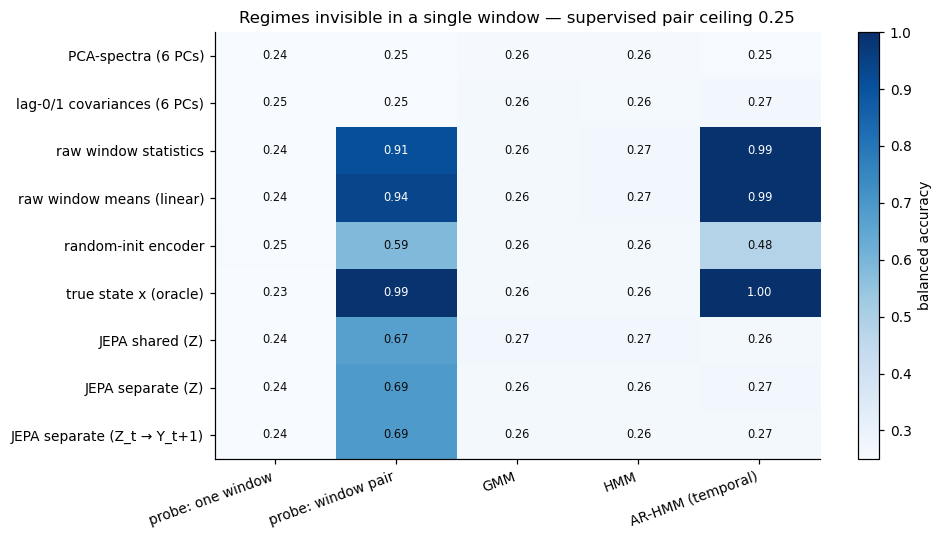

best unsupervised accuracy — cheap baselines: 0.994, JEPA: 0.271, oracle state: 1.000, supervised ceiling: 0.255
single-window probes should all be at chance (the regime is invisible in one window): {'PCA-spectra (6 PCs)': 0.24, 'lag-0/1 covariances (6 PCs)': 0.25, 'raw window statistics': 0.24, 'raw window means (linear)': 0.24, 'random-init encoder': 0.25, 'true state x (oracle)': 0.23, 'JEPA shared (Z)': 0.24, 'JEPA separate (Z)': 0.24, 'JEPA separate (Z_t → Y_t+1)': 0.24}


In [15]:
table = pd.DataFrame(rows).set_index("representation")
ar_cols = [c for c in table.columns if c.startswith("AR-HMM")]
table["AR-HMM (temporal)"] = table[ar_cols].max(1)
table = table.drop(columns=ar_cols)
cols = ["probe: one window", "probe: window pair", "GMM", "HMM", "AR-HMM (temporal)"]
print(f"Balanced accuracy (chance 0.25). Supervised ceiling on labelled window pairs: {ceiling:.3f}")
display(table[cols].round(3))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(table) + 1.2))
im = ax.imshow(table[cols].values.astype(float), cmap="Blues", vmin=0.25, vmax=1, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=20, ha="right"); ax.set_yticks(range(len(table)), table.index)
for i in range(len(table)):
    for j in range(len(cols)):
        ax.text(j, i, f"{table[cols].values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if table[cols].values[i, j] > 0.7 else "#0b0b0b")
ax.grid(False); plt.colorbar(im, label="balanced accuracy")
ax.set_title(f"Regimes invisible in a single window — supervised pair ceiling {ceiling:.2f}")
plt.tight_layout(); plt.show()

best_base = table.loc[["PCA-spectra (6 PCs)", "lag-0/1 covariances (6 PCs)", "raw window statistics",
                       "raw window means (linear)", "random-init encoder"], ["GMM", "HMM", "AR-HMM (temporal)"]].max().max()
best_jepa = table.loc[[i for i in table.index if i.startswith("JEPA")], ["GMM", "HMM", "AR-HMM (temporal)"]].max().max()
print(f"best unsupervised accuracy — cheap baselines: {best_base:.3f}, JEPA: {best_jepa:.3f}, oracle state: "
      f"{table.loc['true state x (oracle)', 'AR-HMM (temporal)']:.3f}, supervised ceiling: {ceiling:.3f}")
print("single-window probes should all be at chance (the regime is invisible in one window):",
      table["probe: one window"].round(2).to_dict())

### How to read the table
* **probe: one window** must be ≈ 0.25 for every representation, which confirms the regime is not in any single window.
* **probe: window pair** is the information available to a supervised reader of that representation. Compare it with the supervised ceiling.
* **GMM / HMM** cluster single-window representations, so they should fail for everyone. Their failure is the point: these are the methods that worked in the spectral benchmark.
* **AR-HMM (temporal)** is the unsupervised readout that fits this kind of regime. A JEPA has demonstrated value when its AR-HMM accuracy beats that of the cheap baselines, the raw window means in particular, which are the honest "linear features + right temporal readout" baseline.